In [12]:
from pathlib import Path

print("Current working directory:", Path.cwd())
print("PDF files:", [p.name for p in Path("data").glob("*.pdf")])

Current working directory: C:\Users\adouc\Downloads\explainable-esg-scoring-nlp
PDF files: ['BNP_Paribas_Rapport_Integre_2024_FR_BD.pdf', 'ifa-2022-consolidated-annual-financial-report-en.pdf', 'Non-Financial-Report-2023.pdf']


In [13]:
!pip install -q pandas numpy scikit-learn pdfminer.six matplotlib lime shap

In [14]:
import logging, re, json, unicodedata
from pathlib import Path
from typing import List, Tuple, Dict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge

logging.getLogger("pdfminer").setLevel(logging.ERROR)

# normalisation texte (minuscules + accents + espaces)
def norm_txt(s: str) -> str:
    s = s.lower()
    s = unicodedata.normalize("NFKD", s)
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = re.sub(r"\s+", " ", s).strip()
    return s

# extraction PDF/TXT (pdfminer → fallback PyMuPDF si dispo)
def read_text_from_path(p: Path) -> str:
    p = Path(p)
    if p.suffix.lower() == ".txt":
        return p.read_text(encoding="utf-8", errors="ignore")
    if p.suffix.lower() == ".pdf":
        # 1) pdfminer
        try:
            from pdfminer.high_level import extract_text
            t = extract_text(str(p)) or ""
            if len(t.strip()) > 100:
                return t
        except Exception:
            pass
        # 2) PyMuPDF
        try:
            import fitz
            doc = fitz.open(str(p))
            t = "\n".join(page.get_text("text") for page in doc)
            if len(t.strip()) > 100:
                return t
        except Exception:
            pass
        return ""  # probablement un scan → OCR requis
    raise ValueError(f"Unsupported file type: {p.suffix}")


In [15]:
# ---- Lexiques démo (à enrichir si besoin) ----
LEXICON_E_FR = ["climat","carbone","co2","émissions","emissions","énergies renouvelables","energie renouvelable","energie","transition","plan de transition","environnement","biodiversité","scope 3","finance verte","taxonomie","pollution","déchets","recyclage","neutralité carbone"]
LEXICON_S_FR = ["diversité","inclusion","santé et sécurité","droits humains","formation","salariés","employés","communauté","satisfaction client","confidentialité","protection des données","bien-être","salaire décent","égalité des chances","travail","syndicat"]
LEXICON_G_FR = ["conseil","comité d audit","comité des risques","administrateurs indépendants","éthique","anticorruption","lanceur d alerte","rémunération","rémunération des dirigeants","gouvernance","conformité","contrôle interne","transparence"]

LEXICON_E_EN = ["climate","carbon","co2","emissions","renewable","renewable energy","energy","transition plan","environment","biodiversity","scope 3","green finance","taxonomy","pollution","waste","recycling","net zero"]
LEXICON_S_EN = ["diversity","inclusion","health and safety","human rights","training","employees","community","customer satisfaction","privacy","data protection","wellbeing","living wage","equal opportunity","labor","union"]
LEXICON_G_EN = ["board","independent directors","audit committee","risk committee","ethics","anti-corruption","whistleblowing","remuneration","executive pay","governance","compliance","internal control","transparency"]

LEXICON_E = sorted(set(map(norm_txt, LEXICON_E_FR + LEXICON_E_EN)))
LEXICON_S = sorted(set(map(norm_txt, LEXICON_S_FR + LEXICON_S_EN)))
LEXICON_G = sorted(set(map(norm_txt, LEXICON_G_FR + LEXICON_G_EN)))

print(f"Lexicon sizes | E:{len(LEXICON_E)} S:{len(LEXICON_S)} G:{len(LEXICON_G)}")


Lexicon sizes | E:31 S:30 G:25


In [16]:
def build_vectorizer(max_features=30000, min_df=1, ngram_range=(1,3)) -> TfidfVectorizer:
    return TfidfVectorizer(
        max_features=max_features,
        min_df=min_df,
        ngram_range=ngram_range,          
        strip_accents="unicode",
        token_pattern=r"(?u)\b[\w\-]{2,}\b"
    )

def make_X(file_paths: List[Path]):
    texts = [norm_txt(read_text_from_path(Path(p))) for p in file_paths]
    vec = build_vectorizer()
    X = vec.fit_transform(texts)
    vocab = vec.get_feature_names_out()
    return X, vocab, texts

def score_row(vocab: np.ndarray, row, lexicon_norm: set, top_k=12):
    items = []
    for idx in row.indices:
        tok = vocab[idx]
        val = float(row[0, idx])
        # vocab sort déjà sans accents 
        if norm_txt(tok) in lexicon_norm:
            items.append((tok, val))
    total = float(np.sum([v for _, v in items]))
    top = sorted(items, key=lambda x: x[1], reverse=True)[:top_k]
    return total, top

def baseline_from_X(X, vocab, names: List[str], top_k=12):
    rows, details = [], {}
    yE, yS, yG = [], [], []
    for i, name in enumerate(names):
        row = X[i]
        e, e_top = score_row(vocab, row, set(LEXICON_E), top_k)
        s, s_top = score_row(vocab, row, set(LEXICON_S), top_k)
        g, g_top = score_row(vocab, row, set(LEXICON_G), top_k)
        yE.append(e); yS.append(s); yG.append(g)
        details[name] = {"top_E": e_top, "top_S": s_top, "top_G": g_top}
    yE, yS, yG = np.array(yE), np.array(yS), np.array(yG)
    ESG = (yE + yS + yG) / 3.0
    df = pd.DataFrame({"document": names, "E_score": yE, "S_score": yS, "G_score": yG, "ESG_score": ESG})
    return df.sort_values("ESG_score", ascending=False).reset_index(drop=True), details, yE, yS, yG

def train_ridge_models(X, yE, yS, yG, alpha=1.0):
    mE = Ridge(alpha=alpha).fit(X, yE)
    mS = Ridge(alpha=alpha).fit(X, yS)
    mG = Ridge(alpha=alpha).fit(X, yG)
    return mE, mS, mG


In [17]:
from pathlib import Path

# Financial reports used for ESG analysis
files = [
    Path("data/BNP_Paribas_Rapport_Integre_2024_FR_BD.pdf"),
    Path("data/Non-Financial-Report-2023.pdf"),
    Path("data/ifa-2022-consolidated-annual-financial-report-en.pdf"),
]

# Output directory for generated results
odir = Path("results")
odir.mkdir(parents=True, exist_ok=True)

print("Output dir:", odir.resolve())

# Verify PDF text extraction
for p in files:
    t = read_text_from_path(p)
    print(p.name, "chars=", len(t))


Output dir: C:\Users\adouc\Downloads\explainable-esg-scoring-nlp\results
BNP_Paribas_Rapport_Integre_2024_FR_BD.pdf chars= 246612
Non-Financial-Report-2023.pdf chars= 1129174
ifa-2022-consolidated-annual-financial-report-en.pdf chars= 3703356


,document,E_score,S_score,G_score,ESG_score
0,Non-Financial-Report-2023.pdf,0.147188,0.086392,0.085341,0.106307
1,ifa-2022-consolidated-annual-financial-report-...,0.044687,0.034349,0.130433,0.069823
2,BNP_Paribas_Rapport_Integre_2024_FR_BD.pdf,0.075367,0.023072,0.035419,0.044619


R^2 (train) — E/S/G: 0.252 0.461 0.673
Saved: results\esg_results_baseline.csv
Saved: results\esg_explanations_top_tokens.json


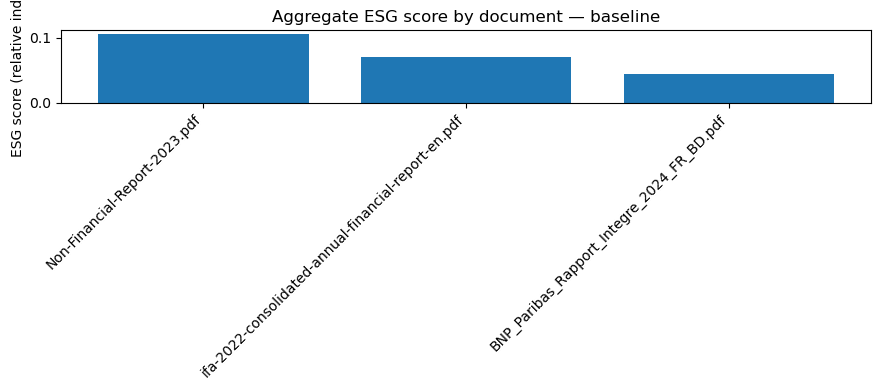

Saved: results\figure_esg_scores_baseline.png


In [18]:
paths = [Path(p) for p in files]
names = [Path(p).name for p in paths]

# TF-IDF
X, vocab, texts = make_X(paths)

# Baseline interprétable
df_base, details, yE, yS, yG = baseline_from_X(X, vocab, names, top_k=12)
display(df_base.head())

# Variante supervisée (lissage baseline)
mE, mS, mG = train_ridge_models(X, yE, yS, yG, alpha=1.0)
print("R^2 (train) — E/S/G:", round(mE.score(X, yE),3), round(mS.score(X, yS),3), round(mG.score(X, yG),3))

# Exports baseline
csv_path  = odir / "esg_results_baseline.csv"
json_path = odir / "esg_explanations_top_tokens.json"
df_base.to_csv(csv_path, index=False, encoding="utf-8")
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(details, f, ensure_ascii=False, indent=2)
print("Saved:", csv_path)
print("Saved:", json_path)

# Figure ESG (matplotlib)
plt.figure(figsize=(9,4))
plt.bar(df_base["document"], df_base["ESG_score"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("ESG score (relative index)")
plt.title("Aggregate ESG score by document — baseline")
plt.tight_layout()
png_esg = odir / "figure_esg_scores_baseline.png"
plt.savefig(png_esg, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", png_esg)


In [19]:
from lime.lime_tabular import LimeTabularExplainer

X_dense = X.toarray()  # sur 2–3 docs, ok
explainer_E = LimeTabularExplainer(
    X_dense,
    feature_names=list(vocab),
    mode="regression",
    discretize_continuous=False,
    sample_around_instance=True
)

i = 0  # <-- choisis le document à expliquer (0,1,2…)
exp_E = explainer_E.explain_instance(X_dense[i], mE.predict, num_features=15)
lime_E = pd.DataFrame(exp_E.as_list(), columns=["feature","weight"])
display(lime_E)

lime_csv = odir / f"lime_top_features_E_doc{i}.csv"
lime_E.to_csv(lime_csv, index=False, encoding="utf-8")
print("Saved:", lime_csv)

# (Option) refaire pour S/G : réutilise explainer_E avec mS / mG


,feature,weight
0,and,0.001094
1,de,-0.001056
2,bank,0.000638
3,of,0.000568
4,deutsche bank,0.000475
5,et,-0.000391
6,to,0.000232
7,deutsche,0.000169
8,les,-0.000168
9,the bank,0.000156


Saved: results\lime_top_features_E_doc0.csv


,feature,shap_value
0,and,-0.001542
1,de,-0.001504
2,of,-0.000812
3,et,-0.000556
4,bank,-0.000498
5,to,-0.000337
6,deutsche bank,-0.000333
7,les,-0.000242
8,la,-0.000226
9,le,-0.000200


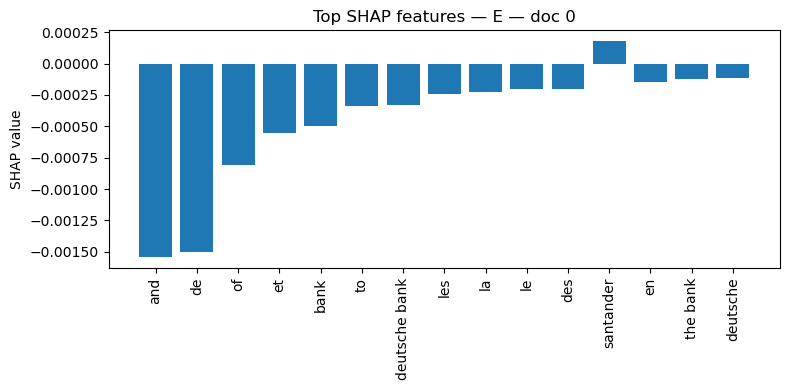

Saved: results\shap_top_features_E_doc0.png


,feature,mean_abs_shap
0,and,0.001028
1,de,0.001003
2,bank,0.000605
3,of,0.000541
4,deutsche bank,0.000444
5,et,0.000371
6,santander,0.000238
7,to,0.000224
8,les,0.000161
9,deutsche,0.000158


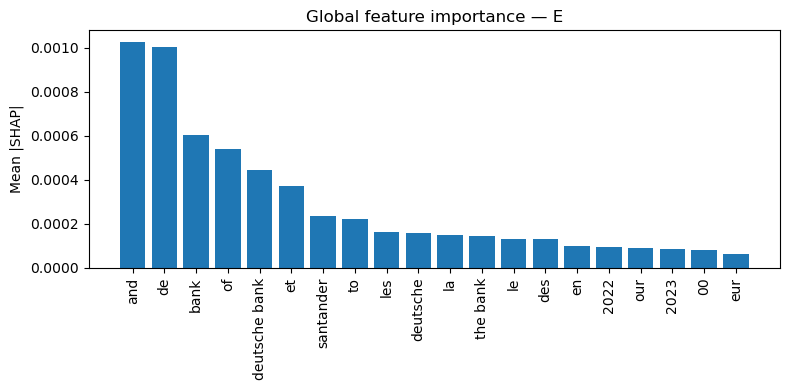

Saved: results\shap_global_importance_E.png


In [20]:
import shap

explainer_shap_E = shap.Explainer(mE, X)  # LinearExplainer auto
sv_E = explainer_shap_E(X)                # shap values

# Local (doc i)
i = 0
vals = sv_E.values[i]
idx = np.argsort(np.abs(vals))[-15:][::-1]
top_feat = [(vocab[j], float(vals[j])) for j in idx]
df_shap_local = pd.DataFrame(top_feat, columns=["feature","shap_value"])
display(df_shap_local)

plt.figure(figsize=(8,4))
plt.bar([f for f,_ in top_feat], [v for _,v in top_feat])
plt.xticks(rotation=90)
plt.ylabel("SHAP value")
plt.title(f"Top SHAP features — E — doc {i}")
plt.tight_layout()
png_shap_local = odir / f"shap_top_features_E_doc{i}.png"
plt.savefig(png_shap_local, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", png_shap_local)

# Globale (moyenne absolue)
mean_abs = np.mean(np.abs(sv_E.values), axis=0)
gidx = np.argsort(mean_abs)[-20:][::-1]
glob_feat = [(vocab[j], float(mean_abs[j])) for j in gidx]
df_shap_global = pd.DataFrame(glob_feat, columns=["feature","mean_abs_shap"])
display(df_shap_global.head(20))

plt.figure(figsize=(8,4))
plt.bar([f for f,_ in glob_feat], [v for _,v in glob_feat])
plt.xticks(rotation=90)
plt.ylabel("Mean |SHAP|")
plt.title("Global feature importance — E")
plt.tight_layout()
png_shap_global = odir / "shap_global_importance_E.png"
plt.savefig(png_shap_global, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", png_shap_global)

# (Option) répéter les 2 blocs pour S/G avec mS, mG


In [21]:
def show_explanations_for(doc_name: str, details_dict: Dict[str, Dict[str, List[Tuple[str, float]]]], top_n=12):
    exp = details_dict.get(doc_name, {})
    for pillar in ["E","S","G"]:
        pairs = exp.get(f"top_{pillar}", [])[:top_n]
        print(f"\n=== Top tokens — {pillar} — {doc_name} ===")
        if not pairs:
            print("  (none)")
        else:
            for tok, w in pairs:
                print(f"  {tok:35s}  {w:.5f}")

for doc in df_base["document"].tolist():
    show_explanations_for(doc, details, top_n=12)



=== Top tokens — E — Non-Financial-Report-2023.pdf ===
  taxonomy                             0.03629
  climate                              0.02951
  emissions                            0.01636
  transition                           0.01545
  energy                               0.01175
  environment                          0.00756
  carbon                               0.00684
  waste                                0.00630
  renewable                            0.00486
  transition plan                      0.00306
  biodiversity                         0.00252
  renewable energy                     0.00225

=== Top tokens — S — Non-Financial-Report-2023.pdf ===
  employees                            0.03025
  human rights                         0.01414
  training                             0.01162
  diversity                            0.00720
  data protection                      0.00693
  inclusion                            0.00469
  privacy                              0.0